# 1. Recolección de datos: web scraping de SINAICA con navegador (Playwright + Chromium)

**Todos los datos del proyecto se obtienen con este scraping.** Un Chromium sin ventana, controlado con Playwright, usa el formulario público de consulta de SINAICA (INECC) igual que lo haría una persona. No se descargan archivos ni se usa ninguna API.

| | |
|---|---|
| **Sitio** | https://sinaica.inecc.gob.mx/data.php?tipo=V (datos validados) y `?tipo=C` (datos crudos) |
| **Qué se raspa** | Ozono (O₃) horario de las estaciones de la red *Valle de México*, enero 2015 → hoy |
| **Script** | `scraper_sinaica_navegador.py` (este notebook lo ejecuta y documenta) |
| **Tiempo** | ~2.5 h para todo el periodo (≈ 4,600 búsquedas, 3 navegadores en paralelo, 1 s de pausa). Es reanudable |
| **Salida** | `datos_scraping/crudo/sinaica_navegador/*.html.gz` (respuesta tal cual), `datos_scraping/largo/*.csv.gz`, `datos_scraping/salida/*` |

### Cómo trabaja el robot (por cada estación y cada mes)
1. Abre el formulario de **datos validados** y, en otra pestaña, el de **datos crudos**.
2. Lee del propio formulario el catálogo de estaciones de la red *Valle de México*.
3. Escribe el nombre de la estación en el **buscador** del menú desplegable y la elige.
4. Espera a que el sitio cargue por AJAX los contaminantes que mide esa estación y elige **Ozono**.
5. Elige *Dato base = Concentraciones horarias* y teclea la **fecha de inicio y fin** del mes.
6. Pulsa **Actualizar** y captura la respuesta que el sitio usa para dibujar la tabla y la gráfica.
7. Si los validados no cubren el 90 % del mes (meses recientes), repite la búsqueda en la pestaña de **crudos**.

### Por qué hace falta un navegador (página dinámica)
La respuesta **no trae una tabla HTML**. Los datos vienen dentro de código JavaScript (`var dat = [...]`), y la tabla y la gráfica (Highcharts) las construye el navegador con `tablaDatos.js` y `graficas.js`. Además, los menús son componentes de JavaScript (bootstrap-select), la lista de contaminantes se carga por AJAX según la estación, y los campos de fecha son calendarios emergentes. Con `requests` + BeautifulSoup sobre la URL no hay nada que leer.

### Rubros que cubre
| Rubro | Evidencia en este notebook |
|---|---|
| **Resultados de búsqueda** | Cada dato sale de llenar y enviar el formulario de búsqueda (estación + contaminante + fechas) |
| **Página dinámica (Selenium/Playwright)** | Chromium controlado con Playwright: buscador, menús AJAX, calendario, botón y datos en JavaScript |

In [1]:
# Instalación (solo instala lo que falte; Chromium se descarga la primera vez)
import importlib.util, subprocess, sys

faltan = [m for m in ("playwright", "pandas", "numpy") if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
prueba = "from playwright.sync_api import sync_playwright\nwith sync_playwright() as p: p.chromium.launch().close()"
if subprocess.run([sys.executable, "-c", prueba], capture_output=True).returncode != 0:
    subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], check=True)
print("Playwright + Chromium listos")

Playwright + Chromium listos


In [2]:
from pathlib import Path
from datetime import date

DIR = Path("datos_scraping")          # todo lo raspado vive aquí, separado de cualquier otra fuente
DESDE = "2015-01"
HASTA = date.today().strftime("%Y-%m")
TRABAJADORES = 3                      # navegadores en paralelo (máximo 3: es un servidor público)
PAUSA = 1.0                           # segundos entre búsquedas de cada navegador
VER_NAVEGADOR = False                 # True: abre la ventana de Chromium y se ve al robot llenar el formulario

## Raspado
Corre el script en un proceso aparte y muestra su avance (una línea por estación terminada). Si se corta, vuelve a ejecutar la celda: lo que ya está en `datos_scraping/` no se vuelve a pedir. Para una prueba rápida, agrega por ejemplo `"--estaciones", "MER", "--desde", "2024-01"`.

In [3]:
import subprocess, sys

cmd = [sys.executable, "-u", "scraper_sinaica_navegador.py", "--dir", str(DIR), "--desde", DESDE, "--hasta", HASTA,
       "--trabajadores", str(TRABAJADORES), "--pausa", str(PAUSA)] + (["--ver"] if VER_NAVEGADOR else [])
with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8") as proc:
    for linea in proc.stdout:
        print(linea, end="")
print("código de salida:", proc.returncode)

(node:15456) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


[sinaica-navegador] 32 estaciones x 143 meses (2015-01 -> 2026-11), 3 navegador(es) en paralelo, pausa 1.0 s


[N3] ATI: 580 valores nuevos (28 s) | total 923 valores, 10 búsquedas, 426/4,576 estación-mes
[N2] AJM: 466 valores nuevos (29 s) | total 1,046 valores, 10 búsquedas, 568/4,576 estación-mes


[N1] ACO: 569 valores nuevos (32 s) | total 1,615 valores, 12 búsquedas, 570/4,576 estación-mes


[N3] CCA: 619 valores nuevos (18 s) | total 2,234 valores, 16 búsquedas, 713/4,576 estación-mes


[N1] BJU: 617 valores nuevos (22 s) | total 2,851 valores, 20 búsquedas, 856/4,576 estación-mes


... (25 outputs left out)

[N2] XAL: 488 valores nuevos (20 s) | total 14,127 valores, 100 búsquedas, 3,575/4,576 estación-mes


[N3] TLA: el formulario no ofrece ozono; se omite


[N3] UAX: 624 valores nuevos (13 s) | total 14,751 valores, 104 búsquedas, 3,718/4,576 estación-mes
[sinaica-navegador] listo en 4.2 min: 104 búsquedas en el formulario, 14,751 valores nuevos en datos_scraping\largo | sin ozono: CHO, CAM, LOM, NTS, SFE, TLA


código de salida: 0


## Evidencia del scraping
1. Captura de pantalla que tomó Chromium después de una búsqueda: formulario lleno y gráfica dibujada por el sitio.
2. Un fragmento de la respuesta cruda del servidor: los datos están dentro de JavaScript, no en una tabla HTML.
3. La bitácora: una fila por cada búsqueda hecha en el formulario.

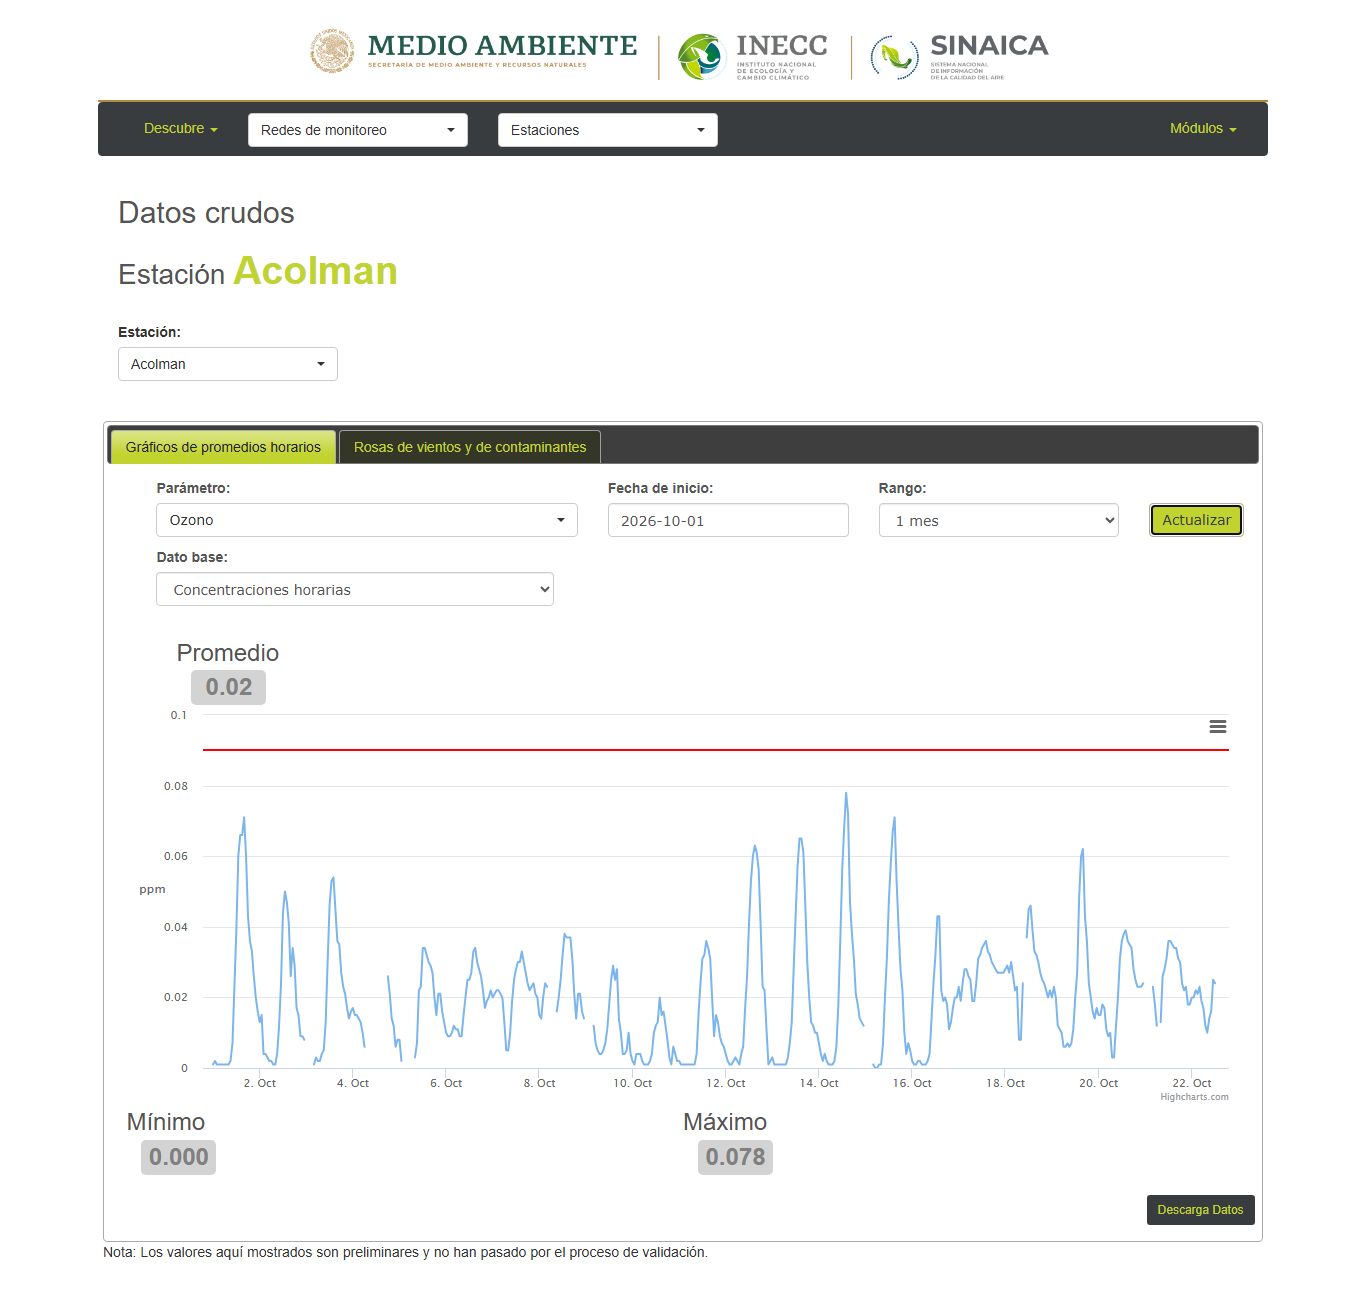

In [4]:
from IPython.display import Image, display
captura = Path("figuras") / "captura_formulario_sinaica.png"
if captura.exists():
    display(Image(filename=str(captura), width=900))
else:
    print("Aún no hay captura: se toma en la primera búsqueda con datos.")

In [5]:
import gzip, re
ejemplos = sorted((DIR / "crudo" / "sinaica_navegador").glob("o3_MER_2016_03_V.html.gz")) or \
           sorted((DIR / "crudo" / "sinaica_navegador").glob("*_V.html.gz"))
with gzip.open(ejemplos[0], "rt", encoding="utf-8") as f:
    html = f.read()
print(ejemplos[0].name, f"({len(html):,} caracteres)")
print("¿Trae <table>?", "<table" in html.lower())
m = re.search(r"var\s+dat\s*=\s*\[.{0,420}", html)
print(m.group(0) + " ..." if m else "sin datos")

o3_MER_2016_03_V.html.gz (68,434 caracteres)
¿Trae <table>? True
var dat = [{"id":"256O316030100","fecha":"2016-03-01","hora":0,"valor":0.012,"bandO":null,"val":1},{"id":"256O316030101","fecha":"2016-03-01","hora":1,"valor":0.003,"bandO":null,"val":1},{"id":"256O316030102","fecha":"2016-03-01","hora":2,"valor":0.016,"bandO":null,"val":1},{"id":"256O316030103","fecha":"2016-03-01","hora":3,"valor":0.015,"bandO":null,"val":1},{"id":"256O316030104","fecha":"2016-03-01","hora":4,"valor":0.011,"b ...


In [6]:
import pandas as pd
bit = pd.read_csv(DIR / "bitacora_sinaica_navegador.csv")
nav = bit[bit["origen"] == "navegador"]
print(f"Búsquedas hechas en el formulario: {len(nav):,} | respuestas HTTP 200: {(nav['http'].astype(str) == '200').mean():.1%}")
print(f"Periodo: {bit['mes'].min()} a {bit['mes'].max()} | estaciones: {bit['estacion'].nunique()}")
print(f"Tiempo medio por búsqueda: {nav['segundos'].mean():.1f} s")
display(nav.assign(anio=nav["mes"].str[:4]).pivot_table(index="anio", columns="tipo", values="estacion",
                                                        aggfunc="size", fill_value=0))

Búsquedas hechas en el formulario: 4,366 | respuestas HTTP 200: 100.0%
Periodo: 2015-01 a 2026-11 | estaciones: 26
Tiempo medio por búsqueda: 3.2 s


tipo,C,V
anio,,
2015,0,312
2016,0,312
2017,0,312
2018,0,312
2019,0,312
2020,0,312
2021,0,312
2022,0,312
2023,0,312


## Limpieza y consolidación
Se unen todos los meses raspados y se aplican las reglas de calidad de `scraper_simat.py`:
- Horas sin dato (`null`) y valores negativos se descartan.
- Validados primero; los crudos solo rellenan horas que no trae la versión validada.
- Valores fuera de rango (> 350 ppb) y picos aislados en datos crudos se excluyen.
- Sensores "pegados" (≥ 6 h idénticas) se marcan.
- Para el máximo diario solo cuentan estación-días con ≥ 18 horas.

In [7]:
import scraper_simat as ss
ss.main(["consolidar", "--contaminante", "o3", "--dir", str(DIR)])

REPORTE DE CALIDAD - O3 (ppb)
Archivos: 3295 | valores leídos: 2,103,288 | fuentes: {'sinaica': 1954891, 'sinaica_prelim': 148397}
Horas fuera de 1..24 descartadas: 0
Cruce sinaica vs sinaica_prelim: 73 horas en común | idénticas 87.7% | dif. media 0.25 ppb
Duplicados resueltos (prioridad rama > opendata > sinaica > web > sinaica_prelim): 73
Negativos eliminados: 0
Fuera de rango plausible (> 350 ppb, excluidos de las tablas): 0
Sensor 'pegado' (>= 6 h idénticas, solo marcado): 143
Picos aislados en datos preliminares (excluidos de las tablas): 6
Valores preliminares (sin validar) en la tabla final: 148,324 | desde 2024-10-18

Periodo: 2015-01-01 a 2026-11-08 | estaciones: 26
Valores finales: 2,103,215 (tabla horaria por estación)
Horas de red: 101,631 | días: 4,317 | días con < 10 estaciones válidas: 9

Estaciones con menor completitud (dentro de su periodo activo):
                min                 max  completitud
estacion                                            
ACO      2015-

## Requisito de tamaño: ≥ 5,500 registros crudos y ≥ 5,000 después de la limpieza
- **Registro crudo** = una fila (estación-hora) en las respuestas que devolvió el formulario.
- **Registro limpio** = una estación-hora con valor válido después de las reglas de calidad.

In [8]:
crudos = int(bit.drop_duplicates(["estacion", "mes", "tipo"], keep="last")["filas_respuesta"].sum())
limpio = pd.read_csv(DIR / "salida" / "o3_horario_estaciones.csv.gz", usecols=["estacion", "fecha", "flag"])
validos = limpio[~limpio["flag"].isin(["rango", "pico"])]
diario = pd.read_csv(DIR / "salida" / "o3_diario_red.csv")
est_dia = validos.groupby(["estacion", "fecha"]).size()
resumen = pd.DataFrame({
    "registros": [crudos, len(validos), int((est_dia >= 18).sum()), len(diario)],
}, index=["Crudos: estación-hora devueltas por el formulario",
          "Limpios: estación-hora válidas",
          "Limpios: estación-día con ≥ 18 h",
          "Serie diaria de la red (máximo diario)"])
display(resumen.style.format("{:,}"))
print("Requisito ≥ 5,500 crudos:", "CUMPLE" if crudos >= 5500 else "NO CUMPLE")
print("Requisito ≥ 5,000 limpios:", "CUMPLE" if len(validos) >= 5000 else "NO CUMPLE")

,registros
Crudos: estación-hora devueltas por el formulario,"2,501,618"
Limpios: estación-hora válidas,"2,103,209"
Limpios: estación-día con ≥ 18 h,"88,911"
Serie diaria de la red (máximo diario),"4,317"


Requisito ≥ 5,500 crudos: CUMPLE
Requisito ≥ 5,000 limpios: CUMPLE


## Validación externa (opcional)
Si está la carpeta `datos_aire/` con los archivos oficiales del SIMAT, se comparan hora por hora con lo raspado. Sirve solo para comprobar que el scraping es correcto: **esos archivos no entran al análisis.**

In [9]:
oficial = Path("datos_aire/salida/o3_horario_estaciones.csv.gz")
if oficial.exists():
    raspado = pd.read_csv(DIR / "salida" / "o3_horario_estaciones.csv.gz", usecols=["fecha", "hora", "estacion", "valor"])
    ofi = pd.read_csv(oficial, usecols=["fecha", "hora", "estacion", "valor", "fuente"])
    ofi = ofi[ofi["fuente"].isin(["opendata", "rama"])]
    x = raspado.merge(ofi, on=["fecha", "hora", "estacion"], suffixes=("_raspado", "_oficial"))
    dif = (x["valor_raspado"] - x["valor_oficial"]).abs()
    print(f"Horas en común con los archivos oficiales: {len(x):,} | idénticas (±0.5 ppb): {(dif < 0.5).mean():.2%} | "
          f"diferencia media: {dif.mean():.3f} ppb")
else:
    print("No está datos_aire/: se omite la validación externa.")

Horas en común con los archivos oficiales: 1,837,348 | idénticas (±0.5 ppb): 99.11% | diferencia media: 0.100 ppb


**Siguientes pasos:** `02_pronostico_arima.ipynb` (ARIMA y proyección) y `03_zonas_clasificacion.ipynb` (PCA, clusterización y clasificación) leen las tablas de `datos_scraping/salida/`.

**Nota sobre estaciones.** El formulario de SINAICA publica 32 estaciones de la red *Valle de México*. Ya no ofrece 8 estaciones históricas (AJU, COY, INN, MPA, MON, MCM, PLA, SJA). De las 32, para 6 (CAM, CHO, LOM, NTS, SFE, TLA) el propio sitio no ofrece ozono: su lista de contaminantes llega vacía. Quedan **26 estaciones con datos de ozono**.